# Our 10-band models on `estimate.fits`

`estimate.fits` holds a toy satellite simulated in 10 bands, from 400 to 914 nm (`message.txt`).
The model in our preprint takes 36 bands from 350 to 1000 nm, so it can't read this file as is.
Two things were needed:

- **New models.** We trained 10 copies of the manuscript's model on these 10 bands, with our simulator set up like the preprint's code (same scene types, materials and blur; noise σ = 0.02); only the bands differ.
- **Normalization.** Our models expect reflectance, from 0 to 1, while the file holds values in
  unknown units, so we convert the file before running the models.

The notebook has three sections:

0. How well the 10-band models do on our own simulated data.
1. How we turn the file into model input.
2. What the models predict on it, and how much that depends on the choices made in section 1.

In [40]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import pvlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, hsv_to_rgb
from astropy.io import fits
from omegaconf import OmegaConf

ROOT = Path("..").resolve()                       # project root
sys.path.insert(0, str(ROOT))                     # the project's src (models, dataset)
from src.data_generation import ID_TO_NAME, N_CLASSES, SpectralLibraryWarning
from src.datasets.hsi import HSIDataset
from src.registry import build_model

warnings.simplefilter("ignore", SpectralLibraryWarning)  # flagged-band reports, see notebook 01

FITS = ROOT / "assets" / "new_input" / "estimate.fits"
MESSAGE_BANDS = [914.286, 800.000, 711.111, 640.000, 581.818, 533.333, 492.308, 457.143,
                 426.667, 400.000]           # nm, in the file's order (message.txt): red to blue

# logs: the project's logs on the cluster, or their sshfs mount on the Mac
LOGDIR = ROOT / "logs"
if not (LOGDIR / "estimate_10band").is_dir():
    LOGDIR = Path.home() / "_remote_data" / "satellites_remote" / "logs"
EXPDIR = LOGDIR / "estimate_10band"
config = OmegaConf.load(EXPDIR / "config.yaml")
data = HSIDataset(config.data.params)            # the generator and library the models saw
LAM = data.cfg.wavelengths_nm                    # band centres in training order: blue to red
assert np.allclose(LAM, sorted(MESSAGE_BANDS))

S1, S2 = "#2a78d6", "#eb6834"                                        # generator: blue, FITS: orange
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8a8f", "#e4e4e2"  # text, ticks/labels, faint lines, grid
# white background, then saturated material colours (golden-ratio hues), so fading shows
HUES = [((i * 0.618) % 1, 0.85, 0.95 if i % 2 else 0.7) for i in range(N_CLASSES - 1)]
MATERIALS = ListedColormap(["white", *(hsv_to_rgb(h) for h in HUES)])
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
})


def window(a, size, centre):
    # size x size pixels around centre, over the last two axes
    (y, x), h = centre, size // 2
    return a[..., y - h:y + h + 1, x - h:x + h + 1]


def show(ax, image, title, **kw):
    ax.imshow(image, interpolation="nearest", **kw)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=8.5)
    ax.spines[["top", "right"]].set_visible(True)

---
## 0. How good are the 10-band models?

Here we compare the test scores of the 10-band models with those of 36-band models trained the
same way; the 36-band setup trains the preprint's model. Each dot is one of the 10 trained
models, and the bar is their mean. We score them on two sets of simulated scenes: satellites only,
as in the preprint, and the training mix of satellites, random shapes and patches. The lines show
the scores reported in the preprint.

`macro_precision` and `fg_binary_accuracy` are the preprint's "material" and "shape" scores;
`miou` measures how well each material is recognised, and `fg_f1` how well the object's outline is
found. This is the best case for the models: data from the simulator they were trained on, at the
same settings.

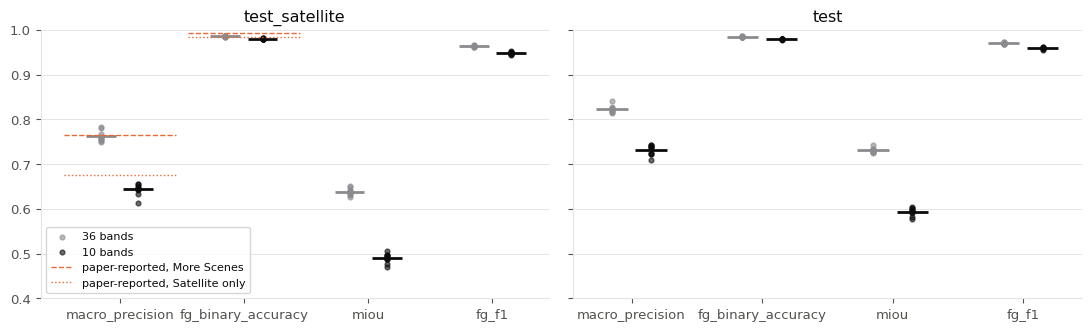

In [41]:
PAPER = {"More Scenes": {"macro_precision": 0.764, "fg_binary_accuracy": 0.992},  # Table 1
         "Satellite only": {"macro_precision": 0.676, "fg_binary_accuracy": 0.983}}
runs = {label: pd.read_csv(LOGDIR / name / "runs.csv")
        for label, name in (("36 bands", "repro_more_scenes"), ("10 bands", "estimate_10band"))}
colors = {"36 bands": MUTED, "10 bands": INK}
shown = ["macro_precision", "fg_binary_accuracy", "miou", "fg_f1"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, test in zip(axes, ("test_satellite", "test")):
    for j, (label, df) in enumerate(runs.items()):
        offset = (j - 0.5) * 0.3
        for i, m in enumerate(shown):
            values = df[f"{test}_{m}"]
            ax.scatter(np.full(len(values), i + offset), values, s=12, color=colors[label], alpha=0.6,
                       label=label if i == 0 else None)
            ax.hlines(values.mean(), i + offset - 0.12, i + offset + 0.12, color=colors[label], lw=2)
    if test == "test_satellite":
        for name, ls in (("More Scenes", "--"), ("Satellite only", ":")):
            for i, m in enumerate(shown):
                if m in PAPER[name]:
                    ax.hlines(PAPER[name][m], i - 0.45, i + 0.45, color=S2, ls=ls, lw=1,
                              label=f"paper-reported, {name}" if i == 0 else None)
    ax.set(xticks=range(len(shown)), xticklabels=shown, title=test, ylim=(0.4, 1.0))
    ax.grid(axis="y")
axes[0].legend(fontsize=8, loc="lower left")
fig.tight_layout()

---
## 1. Turning the file into model input

Our models were trained on reflectance (0 to 1), with bands ordered from blue to red and the
object near the centre of a small frame (15×15 px). The file holds values in unknown units,
related to flux or radiance, with bands ordered from red to blue. We bridge the two in three steps:

- flip the band order and find the object (1.1);
- divide by the sunlight that falls on the object (1.2–1.3);
- choose one overall brightness (1.4).

### 1.1 The cube

We flip the bands to blue-to-red and locate the object: the pixels above 1% of the peak of the
band-summed image. It covers 54 pixels near the centre; the rest of the 512×512 frame is near zero (about 2000 faint pixels, mostly below 10⁻⁵ of the peak). Below, we show each band in a 25×25 px window around the object, all on one grey scale.

shape: (10, 512, 512) | exact zeros: 0.9988 | max: 5.323e+04
object: 54 px, rows 247 - 262 , cols 248 - 252 , centre (254, 250)


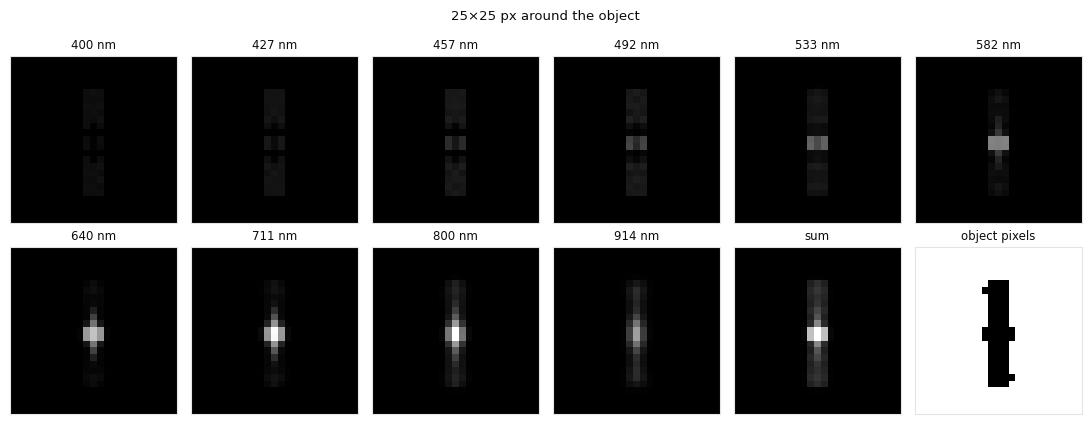

In [42]:
raw = fits.getdata(FITS).astype(float)          # (10, 512, 512), red -> blue
cube = raw[::-1].copy()                          # blue -> red, the models' order
total = cube.sum(0)
footprint = total > 0.01 * total.max()
centre = tuple(int(round(c.mean())) for c in np.nonzero(footprint))

ys, xs = np.nonzero(footprint)
print("shape:", cube.shape, "| exact zeros:", f"{(cube == 0).mean():.4f}", "| max:", f"{cube.max():.4g}")
print("object:", footprint.sum(), "px, rows", ys.min(), "-", ys.max(), ", cols", xs.min(), "-", xs.max(),
      ", centre", centre)

VIEW = 25                                        # px, side of the windows below
fig, axes = plt.subplots(2, 6, figsize=(11, 4.4))
vmax = window(cube, VIEW, centre).max()
for b, ax in enumerate(axes.flat[:10]):
    show(ax, window(cube[b], VIEW, centre), f"{LAM[b]:.0f} nm", cmap="gray", vmin=0, vmax=vmax)
show(axes.flat[10], window(total, VIEW, centre), "sum", cmap="gray")
show(axes.flat[11], window(footprint, VIEW, centre), "object pixels", cmap="gray_r")
fig.suptitle(f"{VIEW}×{VIEW} px around the object", fontsize=9.5)
fig.tight_layout()

### 1.2 The sunlight

Reflectance is the light a surface returns divided by the light falling on it. Here that light is
sunlight, so we take the solar spectrum above the atmosphere (ASTM E-490, from `pvlib`); its shape
is the same anywhere near Earth, LEO or GEO alike. Below, we plot the spectrum and mark its values
at the 10 band centres.

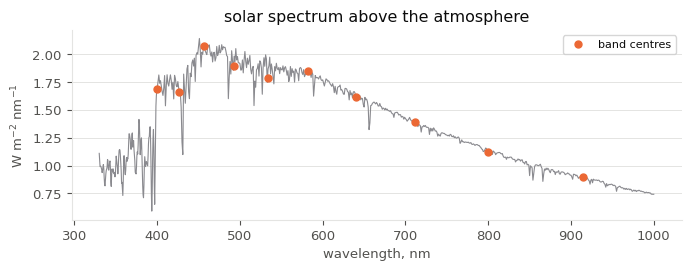

In [43]:
solar = pvlib.spectrum.get_reference_spectra(standard="ASTM G173-03")["extraterrestrial"]  # W m-2 nm-1
E = np.interp(LAM, solar.index, solar.values)

fig, ax = plt.subplots(figsize=(7, 2.8))
grid = solar.loc[330:1000]
ax.plot(grid.index, grid.values, color=MUTED, lw=0.8)
ax.plot(LAM, E, "o", color=S2, ms=5, label="band centres")
ax.set(xlabel="wavelength, nm", ylabel="W m$^{-2}$ nm$^{-1}$", title="solar spectrum above the atmosphere")
ax.grid(axis="y"); ax.legend(fontsize=8)
fig.tight_layout()

### 1.3 From values to reflectance

We don't know how your simulator produced its values, so we compare four ways to read them. Each
divides a pixel's value V in each band by a different quantity:

| reading | assumes V is | divide by |
|---|---|---|
| `V` | reflectance times a constant | nothing |
| `V / E` | reflectance × sunlight at the band centre | E: solar irradiance at the band centre, W m⁻² nm⁻¹ |
| `V / (E·Δλ)` | the same, summed over the band's width | E × Δλ; Δλ ≈ λ²/6400 nm, since the band centres are 6400/n nm |
| `V / (E·Δλ·λ)` | the same, counted in photons | E × Δλ × λ |

Each reading gives reflectance up to one unknown constant, which we set in 1.4. To judge the
readings, we compare the shape of the object's mean spectrum under each one with the spectra of
our 46 materials, each curve divided by its own mean: a reading that produces a shape no material
has is unlikely.

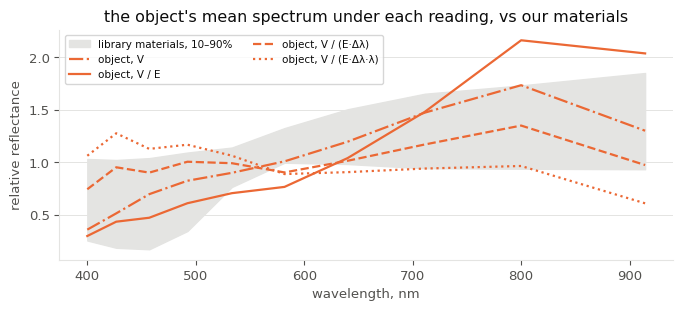

In [44]:
DLAM = LAM ** 2 / 6400                            # band width, nm, for centres at 6400/n nm
READINGS = {                                      # what each band's values are divided by
    "V": np.ones_like(LAM),
    "V / E": E,
    "V / (E·Δλ)": E * DLAM,
    "V / (E·Δλ·λ)": E * DLAM * LAM,
}
library = np.stack([m.pristine for m in data.library.materials.values()])
library = library / library.mean(1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.fill_between(LAM, *np.percentile(library, [10, 90], axis=0), color=GRID,
                label="library materials, 10–90%")
for (name, divisor), ls in zip(READINGS.items(), ("-.", "-", "--", ":")):
    spectrum = (cube[:, footprint] / divisor[:, None]).mean(1)
    ax.plot(LAM, spectrum / spectrum.mean(), color=S2, ls=ls, lw=1.6, label=f"object, {name}")
ax.set(xlabel="wavelength, nm", ylabel="relative reflectance",
       title="the object's mean spectrum under each reading, vs our materials")
ax.grid(axis="y"); ax.legend(fontsize=7.5, ncol=2)
fig.tight_layout()

We use `V / E` by default, because it is the simplest physical reading (reflectance × sunlight). In the plot, `V`
and `V / (E·Δλ)` stay inside our materials' range, while `V / E` rises above it at the red end.
The shape alone can't settle it, so in section 2.2 we run the models under every reading. To
change the default, set `READING`.

In [45]:
READING = "V / E"


def reflectance(scale, reading=None):
    # the cube as reflectance under a reading, times a brightness scale
    return cube / READINGS[reading or READING][:, None, None] * scale

### 1.4 Brightness

Dividing by the sunlight for normalization is fine for spectrum curves, but the overall level remains undetermined.
We try three rules for scaling the values in the cube using a multiplier `k`; the
last two compare the object with the satellite pixels of 500 scenes from the original simulator:

- **max = 1** (default): the brightest object value becomes 1, the most a surface can reflect;
- **median match**: the object's median pixel brightness (mean over bands) equals that of our scenes;
- **95% match**: the same for the 95th percentile, which matches the bright end.

Below, left: per band, the values in our simulated satellite scenes (background and object pixels)
next to the object's values at the default k. Right: the object's pixel brightness under each rule.

max = 1     : object brightness median 0.054, max value 1.00
median match: object brightness median 0.341, max value 6.33
95% match   : object brightness median 0.139, max value 2.58
our simulator, satellites: brightness median 0.341, max value 1.03


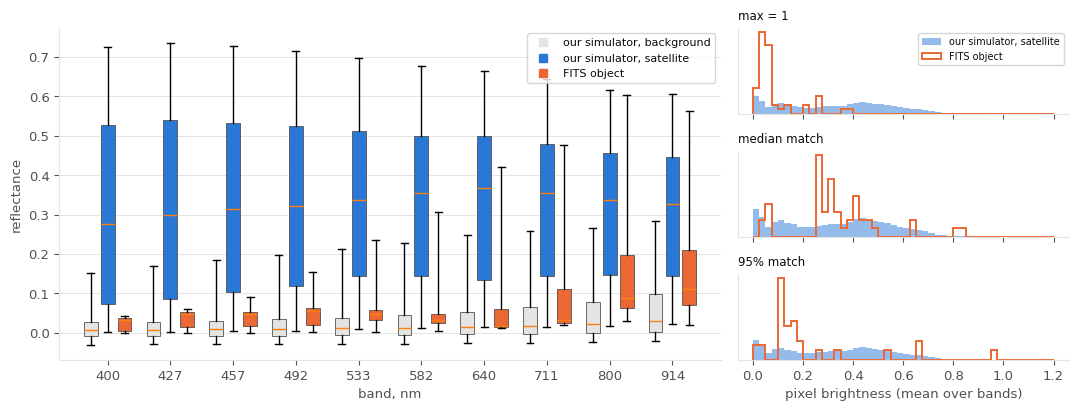

In [46]:
records = data.split("test_satellite")[(0, range(500))].values()
gen_cubes = torch.stack([r["input"] for r in records]).numpy()
gen_masks = torch.stack([r["label"] for r in records]).numpy()
gen_fg = gen_cubes.transpose(1, 0, 2, 3)[:, gen_masks > 0]       # [bands, satellite pixels]
gen_bg = gen_cubes.transpose(1, 0, 2, 3)[:, gen_masks == 0]


def scale_rules(reading=None):
    # k under each rule, for the object's pixels under a reading
    brightness = reflectance(1.0, reading)[:, footprint].mean(0)
    reference = gen_fg.mean(0)
    return {"max = 1": 1 / reflectance(1.0, reading)[:, footprint].max(),
            "median match": np.median(reference) / np.median(brightness),
            "95% match": np.percentile(reference, 95) / np.percentile(brightness, 95)}


SCALES = scale_rules()
SCALE = SCALES["max = 1"]
obj = reflectance(SCALE)[:, footprint]
for name, scale in SCALES.items():
    values = reflectance(scale)[:, footprint]
    print(f"{name:12s}: object brightness median {np.median(values.mean(0)):.3f}, max value {values.max():.2f}")
print(f"our simulator, satellites: brightness median {np.median(gen_fg.mean(0)):.3f}, max value {gen_fg.max():.2f}")

fig = plt.figure(figsize=(11, 4.2))
grid = fig.add_gridspec(len(SCALES), 2, width_ratios=[2, 1])
ax = fig.add_subplot(grid[:, 0])
x = np.arange(len(LAM))
for values, offset, color, label in ((gen_bg, -0.27, GRID, "our simulator, background"),
                                     (gen_fg, 0, S1, "our simulator, satellite"),
                                     (obj, 0.27, S2, "FITS object")):
    parts = ax.boxplot(list(values), positions=x + offset, widths=0.22, whis=(5, 95),
                       showfliers=False, patch_artist=True)
    for box in parts["boxes"]:
        box.set(facecolor=color, edgecolor=INK2, lw=0.6)
    ax.plot([], [], "s", color=color, label=label)
ax.set(xticks=x, xticklabels=[f"{l:.0f}" for l in LAM], xlabel="band, nm", ylabel="reflectance")
ax.grid(axis="y"); ax.legend(fontsize=8)

# one histogram per brightness rule, stacked on a shared x axis
bins = np.linspace(0, 1.2, 49)
hists = []
for r, (name, scale) in enumerate(SCALES.items()):
    hx = fig.add_subplot(grid[r, 1], sharex=hists[0] if hists else None)
    hx.hist(gen_fg.mean(0), bins, density=True, color=S1, alpha=0.5, label="our simulator, satellite")
    hx.hist(reflectance(scale)[:, footprint].mean(0), bins, density=True, histtype="step", color=S2,
            lw=1.4, label="FITS object")
    hx.set(yticks=[]); hx.set_title(name, fontsize=8.5, loc="left")
    hx.tick_params(labelbottom=r == len(SCALES) - 1)
    hists.append(hx)
hists[-1].set_xlabel("pixel brightness (mean over bands)")
hists[0].legend(fontsize=7)
fig.tight_layout()

Let's look at the different settings from the images POV. Each panel shows the object averaged over the 10 bands,
in the 19×19 px window the models get in section 2, for one reading (rows) and one brightness rule
(columns). All panels share a 0–1 grey scale, so values above 1 show as white; the title gives the
image's brightest value. The bottom row shows three of our simulated satellite scenes (15×15 px) on
the same scale.

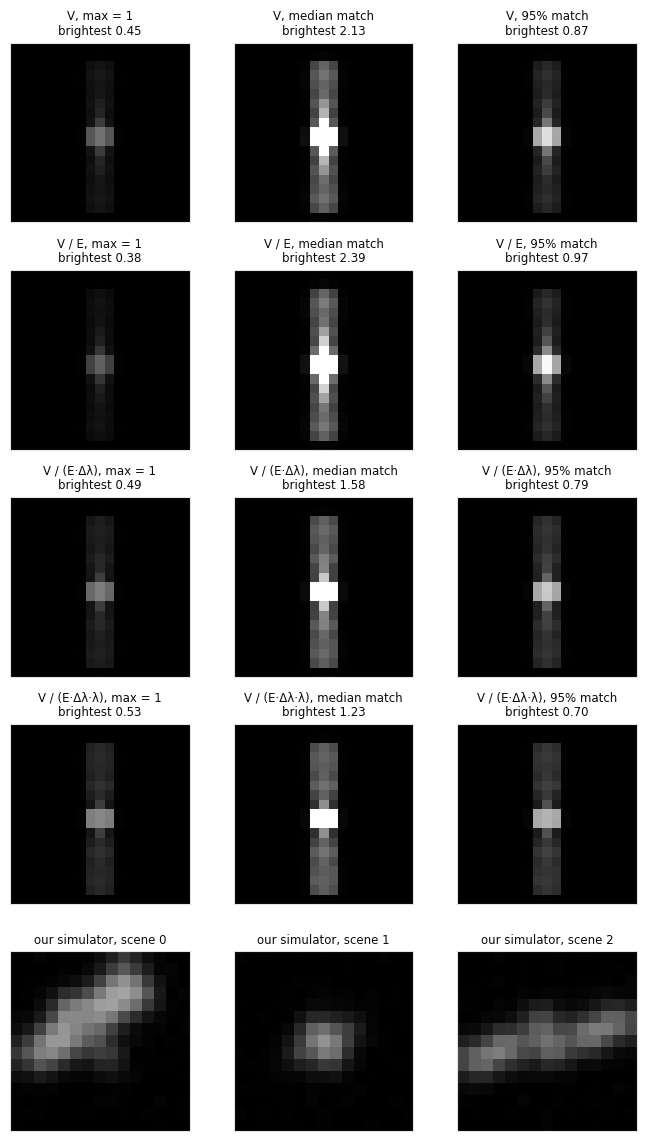

In [47]:
rules = list(SCALES)
fig, axes = plt.subplots(len(READINGS) + 1, len(rules), figsize=(2.3 * len(rules), 2.3 * (len(READINGS) + 1)))
for r, reading in enumerate(READINGS):
    for col, (rule, scale) in enumerate(scale_rules(reading).items()):
        image = window(reflectance(scale, reading), 19, centre).mean(0)
        show(axes[r, col], image, f"{reading}, {rule}\nbrightest {image.max():.2f}", cmap="gray", vmin=0, vmax=1)
for col in range(len(rules)):
    show(axes[-1, col], gen_cubes[col].mean(0), f"our simulator, scene {col}", cmap="gray", vmin=0, vmax=1)
fig.tight_layout()

---
## 2. Applying the models to `estimate.fits`

Here we run all 10 models on the file, converted with the default reading (`V / E`) and
brightness (max = 1). Each model gets a 19×19 px window around the object: a little larger than
the 15×15 px training scenes, because the object is 16 px tall. Each model labels every pixel as
background or one of 46 materials, and we combine the 10 labelings by majority vote.

In the figure, the top row shows the band-summed values, the object pixels, the majority vote and
the share of models agreeing with it; the rows below show each model's labels.

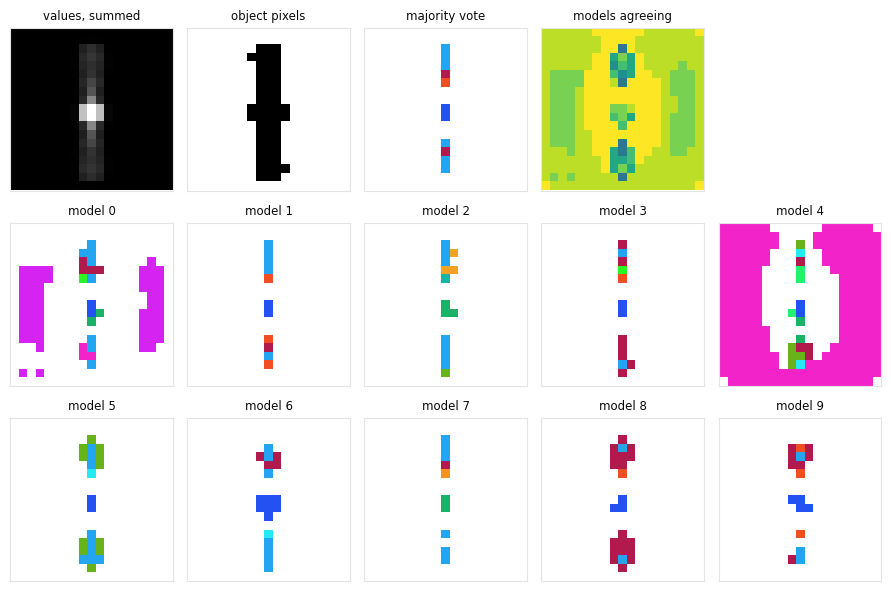

In [48]:
models = []
for rundir in sorted(EXPDIR.glob("run_*"), key=lambda p: int(p.name.split("_")[1])):
    model = build_model(config)
    model.load_state_dict(torch.load(rundir / "model.best.pth", map_location="cpu"))
    models.append(model.eval())


def predict(x):
    # every run's labels for a [bands, H, W] input: [runs, H, W]
    with torch.no_grad():
        t = torch.from_numpy(x[None]).float()
        return torch.stack([m(t).argmax(1)[0] for m in models]).numpy()


def vote(preds):
    # majority label per pixel, and the share of runs that give it
    v = torch.from_numpy(preds).mode(0).values.numpy()
    return v, (preds == v).mean(0)


CROP = 19
preds = predict(window(reflectance(SCALE), CROP, centre))
labels, agreement = vote(preds)
fp = window(footprint, CROP, centre)

fig, axes = plt.subplots(3, 5, figsize=(9, 6))
show(axes[0, 0], window(total, CROP, centre), "values, summed", cmap="gray")
show(axes[0, 1], fp, "object pixels", cmap="gray_r")
show(axes[0, 2], labels, "majority vote", cmap=MATERIALS, vmin=0, vmax=N_CLASSES - 1)
show(axes[0, 3], agreement, "models agreeing", cmap="viridis", vmin=0, vmax=1)
axes[0, 4].axis("off")
for r, ax in enumerate(axes[1:].flat):
    show(ax, preds[r], f"model {r}", cmap=MATERIALS, vmin=0, vmax=N_CLASSES - 1)
fig.tight_layout()



### 2.1 Spectra of the 3 common predicted materials

If a label is right, the pixel's spectrum should resemble that material's spectrum. For the three
materials the vote gives most often, we plot the spectra of the object pixels labelled with them
(orange) next to the material's measured spectra, pristine and irradiated (black).

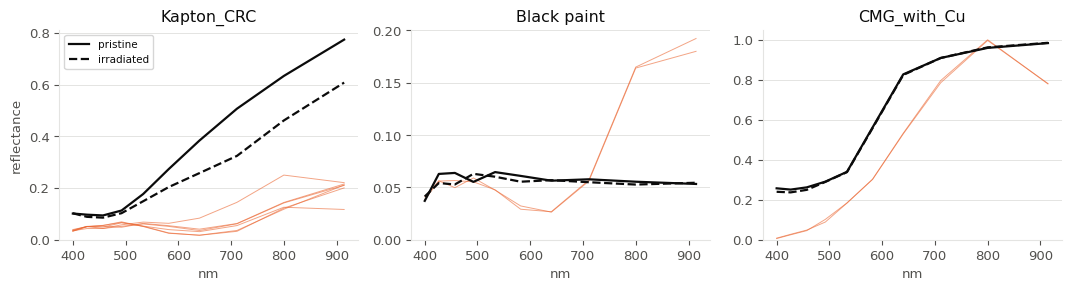

In [49]:
top = [i for i in pd.Series(labels[fp]).value_counts().index if i][:3]  # most common materials
fig, axes = plt.subplots(1, len(top), figsize=(3.6 * len(top), 3), squeeze=False)
image = window(reflectance(SCALE), CROP, centre)
for ax, i in zip(axes[0], top):
    for spectrum in image[:, fp & (labels == i)].T:
        ax.plot(LAM, spectrum, color=S2, lw=0.7, alpha=0.6)
    material = data.library.materials[ID_TO_NAME[i]]
    ax.plot(LAM, material.pristine, color=INK, lw=1.6, label="pristine")
    if material.irradiated is not None:
        ax.plot(LAM, material.irradiated, color=INK, lw=1.6, ls="--", label="irradiated")
    ax.set(title=ID_TO_NAME[i], xlabel="nm", ylim=(0, None)); ax.grid(axis="y")
axes[0, 0].set_ylabel("reflectance"); axes[0, 0].legend(fontsize=7.5)
fig.tight_layout()

### 2.2 How much do the reading and the brightness matter?

In section 1 we had to guess how to read the file's values and how bright to make them. Here we
repeat the prediction for every reading and brightness rule, in the same 19×19 px window.

In the figure, rows are readings and columns are brightness rules. Each panel shows the majority
vote, faded where the models disagree: a strong colour means most of the 10 models give that label.
The top row repeats the input, the summed values and the object pixels. Ideally, the background
stays white and the object gets strong colours.

In [50]:
def scores(v, agree):
    # summary numbers for one setting's vote and agreement
    return {"background labelled as material": (v[~fp] > 0).mean(),
            "object labelled as material": (v[fp] > 0).mean(),
            "object keeps its default label": (v[fp] == labels[fp]).mean(),
            "models agreeing on the object": agree[fp].mean()}


def faded(v, agree):
    # vote colours, faded toward white where the models disagree
    rgb = MATERIALS(v)[..., :3]
    return 1 - agree[..., None] * (1 - rgb)


results = []                                     # (setting, vote, agreement)
for reading in READINGS:
    for rule, scale in scale_rules(reading).items():
        x = window(reflectance(scale, reading), CROP, centre)
        results.append(({"reading": reading, "brightness": rule, "window": CROP}, *vote(predict(x))))
for size in (33, 65, 129, 512):  # 15 would cut the object
    x = reflectance(SCALE)
    frame, at = (x, centre) if size == 512 else (window(x, size, centre), (size // 2, size // 2))
    setting = {"reading": READING, "brightness": "max = 1", "window": size}
    results.append((setting, *vote(window(predict(frame), CROP, at))))

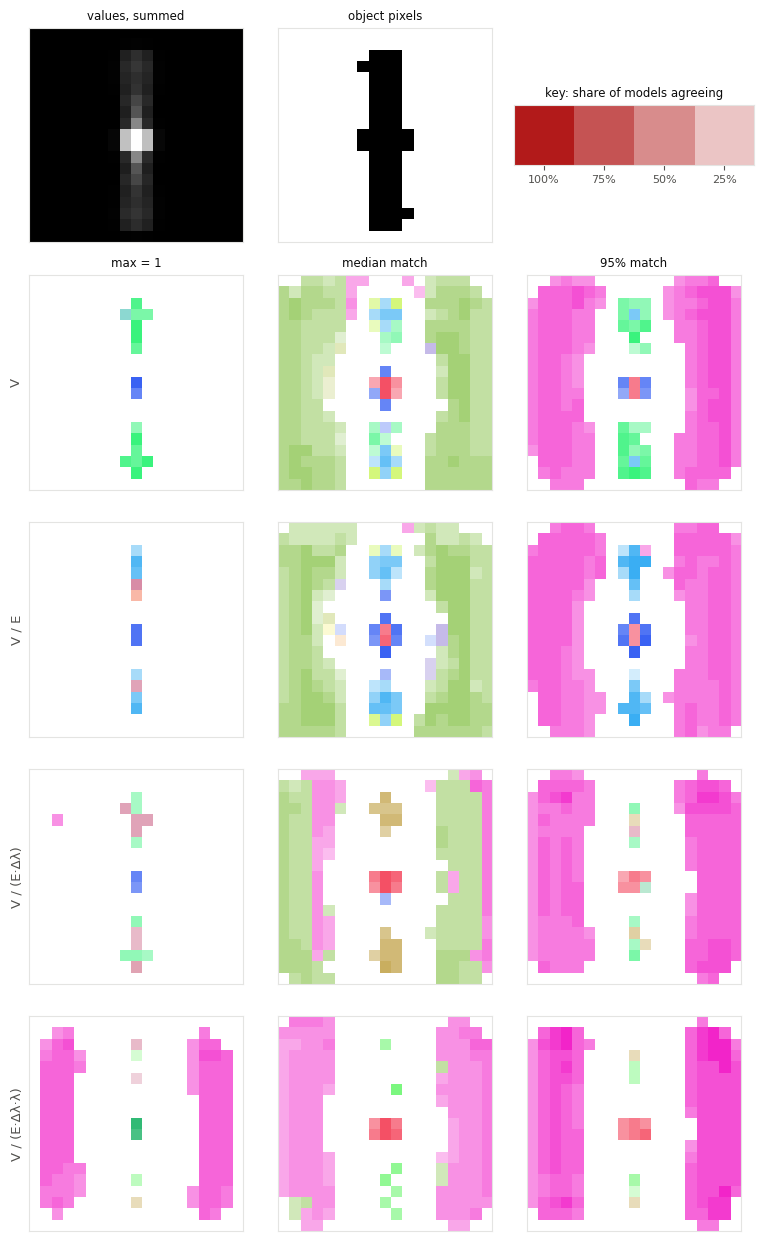

In [51]:
rules = list(SCALES)
found = {(s["reading"], s["brightness"]): (v, a) for s, v, a in results if s["window"] == CROP}
fig, axes = plt.subplots(1 + len(READINGS), len(rules), figsize=(2.6 * len(rules), 2.5 * (1 + len(READINGS))))

# top row: the input, and a key to the colours
show(axes[0, 0], window(total, CROP, centre), "values, summed", cmap="gray")
show(axes[0, 1], fp, "object pixels", cmap="gray_r")
shares = np.array([1, 0.75, 0.5, 0.25])
show(axes[0, 2], faded(np.full((1, len(shares)), 1), shares[None]), "key: share of models agreeing")
axes[0, 2].set_xticks(range(len(shares)), [f"{s:.0%}" for s in shares], fontsize=8)

# one row per reading, one column per brightness rule
for r, reading in enumerate(READINGS, start=1):
    for col, rule in enumerate(rules):
        show(axes[r, col], faded(*found[(reading, rule)]), rule if r == 1 else "")
    axes[r, 0].set_ylabel(reading, fontsize=9.5)
fig.tight_layout()

The same settings in numbers: the share of background pixels labelled as a material (ideally 0),
the share of object pixels labelled as a material, the share of object pixels that keep the label
they get at the defaults (`V / E`, max = 1), and the share of models agreeing on the object's
pixels.

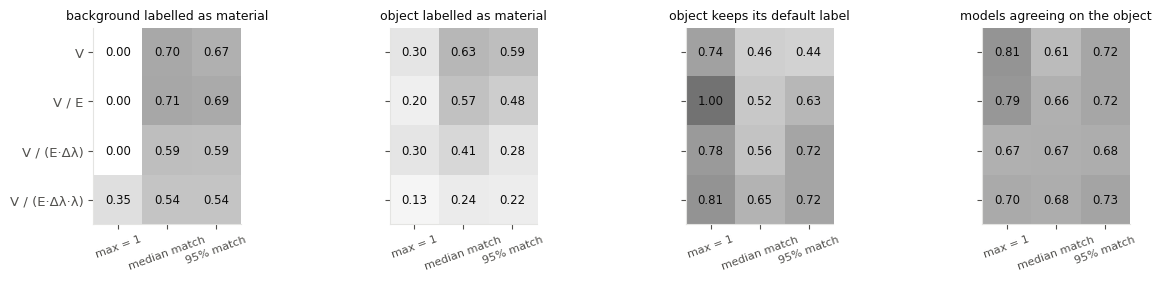

In [52]:
table = pd.DataFrame([{**s, **scores(v, a)} for s, v, a in results if s["window"] == CROP])
fig, axes = plt.subplots(1, 4, figsize=(13, 2.9))
for ax, column in zip(axes, list(scores(labels, agreement))):
    values = table.pivot(index="reading", columns="brightness", values=column).loc[list(READINGS), rules]
    ax.imshow(values.to_numpy(), cmap="Greys", vmin=0, vmax=1.6)
    for (i, j), value in np.ndenumerate(values.to_numpy()):
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8.5)
    ax.set_xticks(range(len(rules)), rules, fontsize=8, rotation=20)
    ax.set_yticks(range(len(READINGS)), list(READINGS) if ax is axes[0] else [])
    ax.set_title(column, fontsize=9)
fig.tight_layout()

### 2.3 Does the window size matter?

Two layers of the model average over the whole image (GroupNorm and the squeeze-and-excitation
block), so the window we cut around the object can change the result; in training, the object
filled 20–30% of a 15×15 px frame. Here we run the models on larger windows, at the default reading
and brightness, and compare the 19×19 px centre of each result with the default window. The panels
use the same faded colours as in 2.2, and the table gives the same numbers.

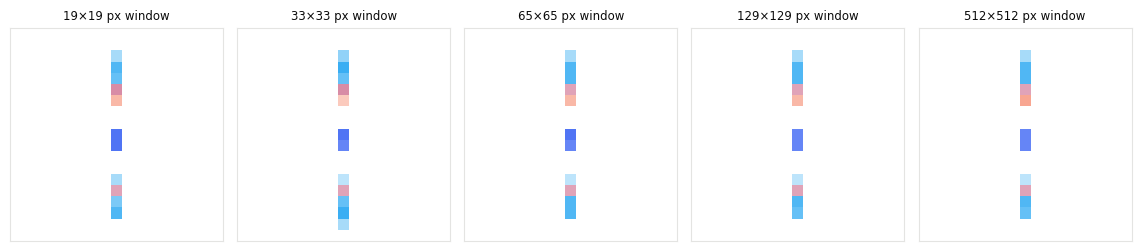

In [53]:
windows = [(s, v, a) for s, v, a in results if (s["reading"], s["brightness"]) == (READING, "max = 1")]
fig, axes = plt.subplots(1, len(windows), figsize=(2.3 * len(windows), 2.6))
for ax, (s, v, a) in zip(axes, windows):
    show(ax, faded(v, a), f"{s['window']}×{s['window']} px window")
fig.tight_layout()